# TAREA 2: Clasificación de microplásticos (sin aprendizaje profundo)

Pasos:
1. Cargar las tres imágenes de entrenamiento (fragmentos, pellets y alquitrán).
2. Segmentar las partículas con umbralizado y contornos, como en la práctica.
3. Extraer características geométricas (las de SMACC) y de color de cada partícula.
4. Aprender el **patrón** de cada clase: el valor medio de sus características.
5. Clasificar las partículas de la imagen de test buscando el patrón más parecido.
6. Comparar con las anotaciones del CSV: métricas, F1 y matriz de confusión.

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

## 1. Cargar las imágenes de entrenamiento

Cada imagen contiene una sola clase, así que todas sus partículas tienen la misma etiqueta. Como las fotos son muy grandes (4608x3456), se reducen a la cuarta parte.

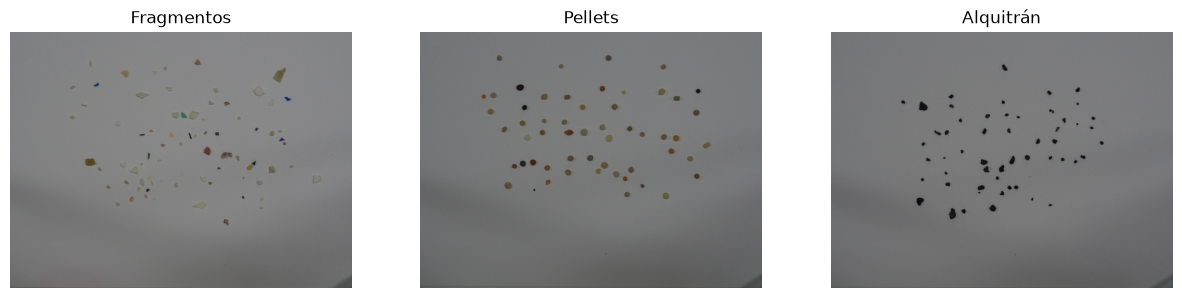

In [2]:
rutas = {
    'FRA': 'img/fragment-03-olympus-10-01-2020.JPG',
    'PEL': 'img/pellet-03-olympus-10-01-2020.JPG',
    'TAR': 'img/tar-03-olympus-10-01-2020.JPG',
}
nombres = {'FRA': 'Fragmentos', 'PEL': 'Pellets', 'TAR': 'Alquitrán'}

imagenes = {}
plt.figure(figsize=(15, 4))
for i, clase in enumerate(rutas):
    img = cv2.imread(rutas[clase])
    img = cv2.resize(img, None, fx=0.25, fy=0.25)
    imagenes[clase] = img
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(nombres[clase])
    plt.axis('off')
plt.show()

## 2. Segmentar las partículas

El fondo no tiene la misma iluminación en toda la imagen, así que un umbral fijo sobre los grises no sirve. Se hace lo siguiente:

1. Se pasa a grises y se normaliza el rango (`cv2.normalize`) para que todas las imágenes vayan de 0 a 255.
2. Se estima el **fondo** con un `medianBlur` muy grande: las partículas desaparecen y sólo queda la iluminación.
3. Se calcula la **diferencia** entre la imagen y el fondo con `cv2.absdiff`. Así destacan tanto las partículas oscuras como las claras.
4. Se **umbraliza** la diferencia: un píxel es partícula si se separa más de 12 niveles del fondo. Otsu no funciona bien aquí porque casi todo es fondo.
5. Con apertura y cierre morfológicos se quitan puntos sueltos y se rellenan huecos.
6. Se buscan los **contornos externos** y se descartan los muy pequeños.

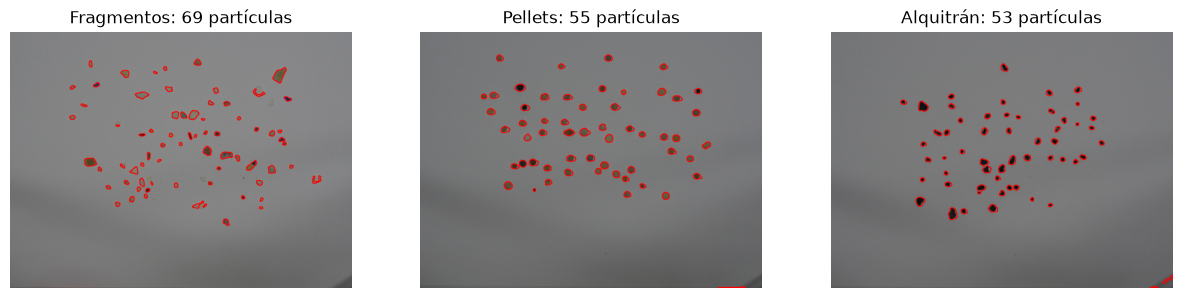

In [ ]:
def segmentar(img, tam_fondo=51, umbral=12, area_min=40):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gris = cv2.normalize(gris, None, 0, 255, cv2.NORM_MINMAX)

    #NOS QUEDAMOS SOLO CON LAS PARTICULAS PARA QUE NO HAYA PROBLEMAS CON EL BRILLO DEL FONDO; quedarse con lo que NO es fondo
    fondo = cv2.medianBlur(gris, tam_fondo)
    diferencia = cv2.absdiff(gris, fondo) #Resta píxel a píxel la imagen real menos el fondo, y se queda con el valor absoluto
    diferencia = cv2.GaussianBlur(diferencia, (5, 5), 0) # SE promedia con los vecinos que valen casi 0, bajan y ya no superan el umbral.

    #UMBRALIZAMOS Y SUAVIZAMOS
    _, binaria = cv2.threshold(diferencia, umbral, 255, cv2.THRESH_BINARY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel) #a operación de apertura, que borra los puntitos blancos sueltos (el ruido).
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel) #la operación de cierre, que tapa los agujeros negros dentro de las partículas y une grietas pequeñas
    

    #SACAMOS LOS CONTORNOS; convierte las manchas blancas en contornos, quita las demasiado pequeñas y devuelve los resultados.
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE) # contorno exterior de cada partícula--> EXTERNAL ; APROX --> que en los tramos rectos solo guarda los extremos
    contornos = [c for c in contornos if cv2.contourArea(c) > area_min]
    return contornos, gris, fondo


plt.figure(figsize=(15, 4))
for i, clase in enumerate(imagenes):
    img = imagenes[clase]
    contornos, gris, fondo = segmentar(img)

    vis = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    cv2.drawContours(vis, contornos, -1, (255, 0, 0), 2)
    plt.subplot(1, 3, i + 1)
    plt.imshow(vis)
    plt.title(f'{nombres[clase]}: {len(contornos)} partículas')
    plt.axis('off')
plt.show()

## 3. Extraer características

Para cada contorno se calculan las características geométricas del trabajo SMACC. Se usan sólo **relaciones**, sin área ni perímetro sueltos, porque la imagen de test tiene otra resolución y esos valores no serían comparables:

- **Compacidad**: P² / A (un círculo da 4π ≈ 12.6; cuanto más irregular, mayor).
- **Relación con el contenedor**: área de la partícula / área de su rectángulo.
- **Relación ancho/alto** del rectángulo contenedor.
- **Relación de ejes** de la elipse ajustada (menor / mayor).
- **Relación de distancias**: distancia mínima / máxima del centroide al contorno.
- **Solidez**: área / área de su envolvente convexa (de la documentación de contornos de OpenCV).

Y dos de apariencia:
- **Brillo**: gris medio de la partícula dividido entre el gris del fondo en esa zona (< 1 si es más oscura que el fondo).
- **Saturación** media en HSV (el alquitrán es negro, sin color).

In [5]:
def caracteristicas(c, gris, fondo, hsv):
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c) #RECTANGULO
    (_, _), ejes, _ = cv2.fitEllipse(c) #EJE DE LA ECLIPSE

    # Centroide y distancias del centroide a cada punto del contorno
    M = cv2.moments(c)
    cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
    distancias = np.sqrt((c[:, 0, 0] - cx)**2 + (c[:, 0, 1] - cy)**2)

    # Máscara de la partícula para medir su color
    mascara = np.zeros(gris.shape, np.uint8)
    cv2.drawContours(mascara, [c], -1, 255, -1)

    return {
        'compacidad': perimetro**2 / area,
        'rel_contenedor': area / (w * h),
        'rel_ancho_alto': min(w, h) / max(w, h),
        'rel_elipse': min(ejes) / max(ejes),
        'rel_distancias': distancias.min() / distancias.max(),
        'solidez': area / cv2.contourArea(cv2.convexHull(c)),
        'brillo': cv2.mean(gris, mascara)[0] / cv2.mean(fondo, mascara)[0],
        'saturacion': cv2.mean(hsv, mascara)[1],
        'cx': cx, 'cy': cy,   # posición, sólo para comparar con las anotaciones
    }


CARACT = ['compacidad', 'rel_contenedor', 'rel_ancho_alto', 'rel_elipse',
          'rel_distancias', 'solidez', 'brillo', 'saturacion']

filas = []
for clase, img in imagenes.items():
    contornos, gris, fondo = segmentar(img)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    for c in contornos:
        datos = caracteristicas(c, gris, fondo, hsv) # HSV: qué color, cuánto color y cuánta luz; BGR: cuánta luz de cada color ; el alquitrán (saturación baja), plásticos de color (saturación alta).
        datos['clase'] = clase
        filas.append(datos)

entreno = pd.DataFrame(filas)
print('Partículas de entrenamiento por clase:')
print(entreno['clase'].value_counts())
entreno[CARACT + ['clase']]

Partículas de entrenamiento por clase:
clase
FRA    69
PEL    55
TAR    53
Name: count, dtype: int64


,compacidad,rel_contenedor,rel_ancho_alto,rel_elipse,rel_distancias,solidez,brillo,saturacion,clase
0,16.913096,0.619048,0.913043,0.676132,0.484819,0.928571,0.667788,55.885196,FRA
1,15.411753,0.643519,0.750000,0.703730,0.604495,0.952055,0.862389,47.035294,FRA
2,24.749368,0.378698,1.000000,0.427047,0.269211,0.805031,0.897343,38.560976,FRA
3,15.158957,0.691406,1.000000,0.884934,0.695542,0.954178,0.845595,27.810945,FRA
4,41.898836,0.293886,0.666667,0.383694,0.189452,0.658564,0.906388,31.363112,FRA
...,...,...,...,...,...,...,...,...,...
172,14.521883,0.685662,0.941176,0.848753,0.704727,0.973890,0.557143,15.009524,TAR
173,14.394919,0.673280,0.857143,0.797286,0.722680,0.971374,0.479339,21.323843,TAR
174,15.234312,0.655844,0.954545,0.800047,0.652732,0.961905,0.575959,15.975976,TAR
175,15.213127,0.652381,0.840000,0.729660,0.645672,0.966150,0.560353,12.943850,TAR


## 4. Aprender los patrones de cada clase

El **patrón** de una clase es la media de cada característica sobre todas sus partículas de entrenamiento. En la tabla se ve en qué se diferencian:
- Los **pellets** son los más redondos: tienen las relaciones de elipse, de distancias y de contenedor más altas y la mayor solidez.
- Los **fragmentos** son los más irregulares: esas mismas relaciones son las más bajas.
- El **alquitrán** es el más oscuro (brillo bajo) y casi no tiene color (saturación baja).
- La compacidad sale parecida en las tres clases: a esta resolución el contorno tiene “escalones” que hacen crecer el perímetro, así que distingue poco.

In [6]:
patrones = entreno.groupby('clase')[CARACT].mean()
patrones.round(3)

,compacidad,rel_contenedor,rel_ancho_alto,rel_elipse,rel_distancias,solidez,brillo,saturacion
clase,,,,,,,,
FRA,19.121,0.597,0.803,0.664,0.497,0.915,0.779,43.767
PEL,18.642,0.684,0.814,0.776,0.662,0.960,0.691,59.430
TAR,16.576,0.654,0.849,0.746,0.615,0.952,0.554,13.529


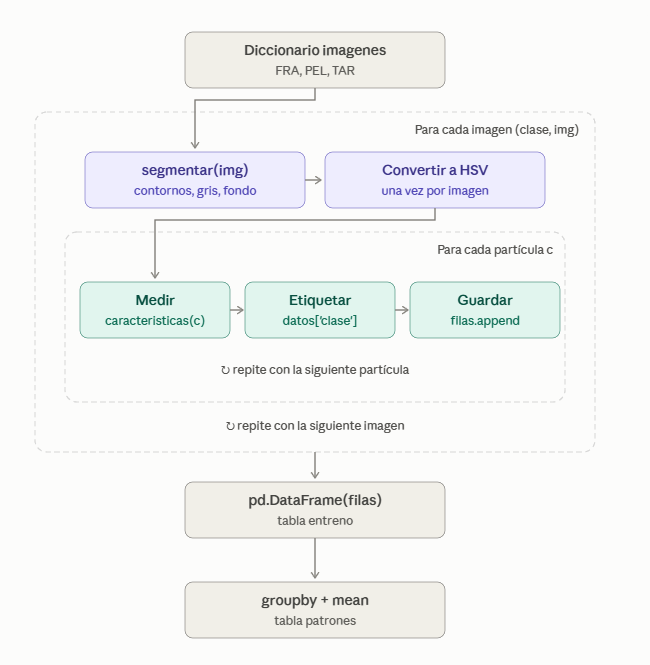

Para clasificar una partícula nueva se mide a qué patrón se parece más (la **distancia** más pequeña). Como las características tienen escalas muy distintas (la saturación llega a 100 y las relaciones están entre 0 y 1), antes se **normaliza** cada una restando su media y dividiendo por su desviación típica, ambas calculadas con los datos de entrenamiento.

Menor diferencia, mayor parecido

Normaliza las características de cada partícula con la media y la desviación del entrenamiento, calcula su distancia euclídea a los patrones medios de FRA, PEL y TAR, y le asigna la clase cuyo patrón está más cerca.

In [11]:
media = entreno[CARACT].mean()
desviacion = entreno[CARACT].std()
patrones_norm = (patrones - media) / desviacion


def clasificar(tabla):
    x = ((tabla[CARACT] - media) / desviacion).values
    # Distancia de cada partícula al patrón de cada clase
    dist = np.array([np.linalg.norm(x - patrones_norm.loc[clase].values, axis=1)
                     for clase in patrones_norm.index])
    return patrones_norm.index[dist.argmin(axis=0)].values

# Comprobación sobre las propias imágenes de entrenamiento
pred_entreno = clasificar(entreno)
print(f"Acierto sobre entrenamiento: {accuracy_score(entreno['clase'], pred_entreno):.3f}")
print(f"F1 (macro) sobre entrenamiento: {f1_score(entreno['clase'], pred_entreno, average='macro'):.3f}")

Acierto sobre entrenamiento: 0.780
F1 (macro) sobre entrenamiento: 0.782


## 5. Clasificar las partículas de la imagen de test

Se segmenta y se extraen las características de la misma forma. La imagen de test no se ha usado para nada de lo anterior.

Partículas detectadas en test: 103
prediccion
FRA    79
PEL    17
TAR     7
Name: count, dtype: int64


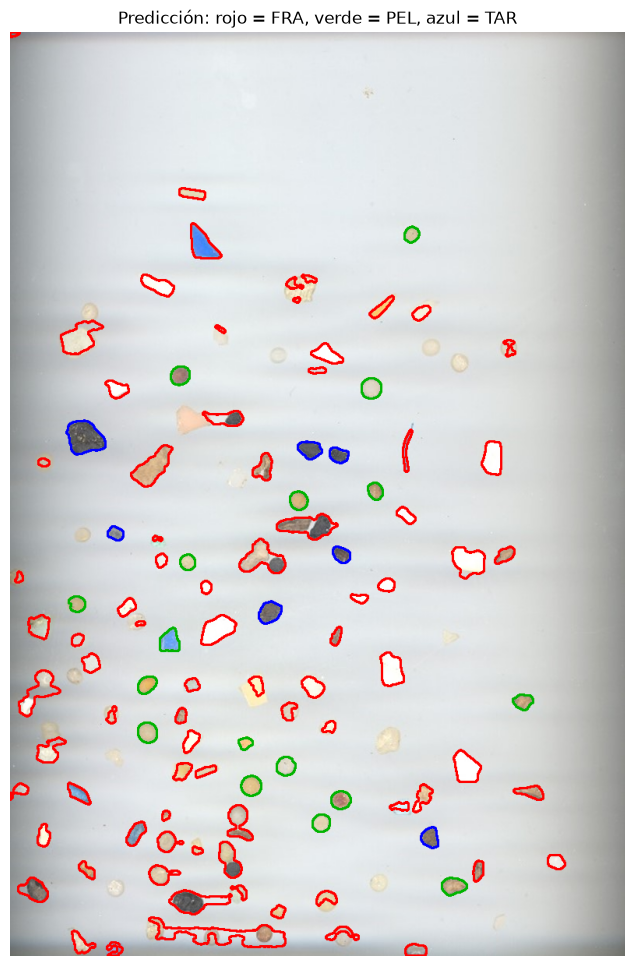

In [8]:
img_test = cv2.imread('img/MPs_test.jpg')
contornos_test, gris_t, fondo_t = segmentar(img_test)
hsv_t = cv2.cvtColor(img_test, cv2.COLOR_BGR2HSV)

test = pd.DataFrame([caracteristicas(c, gris_t, fondo_t, hsv_t) for c in contornos_test])
test['prediccion'] = clasificar(test)
print(f'Partículas detectadas en test: {len(test)}')
print(test['prediccion'].value_counts())

colores = {'FRA': (255, 0, 0), 'PEL': (0, 180, 0), 'TAR': (0, 0, 255)}
vis = cv2.cvtColor(img_test, cv2.COLOR_BGR2RGB)
for c, pred in zip(contornos_test, test['prediccion']):
    cv2.drawContours(vis, [c], -1, colores[pred], 2)

plt.figure(figsize=(8, 12))
plt.imshow(vis)
plt.title('Predicción: rojo = FRA, verde = PEL, azul = TAR')
plt.axis('off')
plt.show()

## 6. Comparar con las anotaciones

Para cada caja anotada en *MPs_test_bbs.csv* se busca la partícula detectada cuyo centroide cae dentro de la caja. Si no hay ninguna, esa anotación cuenta como **no detectada** y no entra en la matriz de confusión.

In [12]:
anotaciones = pd.read_csv('MPs_test_bbs.csv')

y_real, y_pred = [], []
no_detectadas = 0
for _, fila in anotaciones.iterrows():
    dentro = test[(test['cx'] >= fila['x_min']) & (test['cx'] <= fila['x_max']) &
                  (test['cy'] >= fila['y_min']) & (test['cy'] <= fila['y_max'])]
    if len(dentro) > 0:
        y_real.append(fila['label'])
        y_pred.append(dentro['prediccion'].iloc[0])
    else:
        no_detectadas += 1

print(f'Anotaciones: {len(anotaciones)}  emparejadas: {len(y_real)}  no detectadas: {no_detectadas}')

Anotaciones: 120  emparejadas: 97  no detectadas: 23


## 7. Métricas y matriz de confusión

support = partículas reales hay de cada clase

Accuracy (TP/(n))= 0.742
Precision (TP/(TP+FP)) = 0.769
Recall (TP/(TP+FN)) = 0.742
F1 Score (2*(precision*recall)/(precision+recall)) = 0.724

              precision    recall  f1-score   support

         FRA      0.712     0.945     0.812        55
         PEL      0.765     0.464     0.578        28
         TAR      1.000     0.500     0.667        14

    accuracy                          0.742        97
   macro avg      0.826     0.637     0.686        97
weighted avg      0.769     0.742     0.724        97



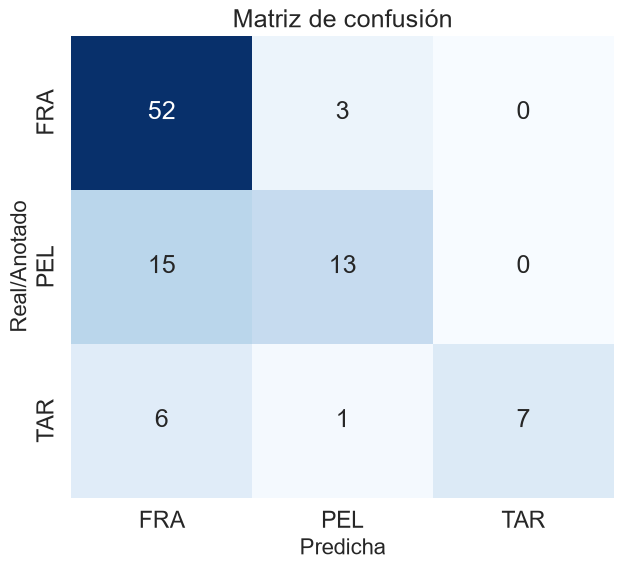

In [13]:
clases = ['FRA', 'PEL', 'TAR']

accuracy = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred, average='weighted')
recall = recall_score(y_real, y_pred, average='weighted')
f1score = f1_score(y_real, y_pred, average='weighted')

print(f"Accuracy (TP/(n))= {accuracy:.3f}")
print(f"Precision (TP/(TP+FP)) = {precision:.3f}")
print(f"Recall (TP/(TP+FN)) = {recall:.3f}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score:.3f}\n")

# Precision, recall y F1 de cada clase
print(classification_report(y_real, y_pred, labels=clases, digits=3))

conf_matrix = confusion_matrix(y_real, y_pred, labels=clases)
plt.figure(figsize=(7, 6))
sns.set(font_scale=1.5)
ax = sns.heatmap(conf_matrix, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=clases, yticklabels=clases)
ax.set_xlabel('Predicha', fontsize=16)
ax.set_ylabel('Real/Anotado', fontsize=16)
plt.title('Matriz de confusión')
plt.show()
sns.set(font_scale=1.0)